# Beyond: ML and fairness tests with a measured size and power, a permutation reference for shift and a Beta-Binomial coverage null

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 02, 04 and 07 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- define the **size** (the rejection rate when nothing is wrong) and the **power** (the rejection rate against a planted defect) of a validation test, and give each with its Monte Carlo standard error;
- measure the size of the split-conformal coverage test under a binomial null and under the Beta-Binomial null the engine uses, at three ratios of test window to calibration window;
- measure how often a fixed AUC-drop rule fires on the worst subsample when there is no shift, and compare it with the permutation reference of the engine, in size and power;
- measure the size and the power of the situation-testing light at the two amber cut points;
- see the corrected tests in the committed rows of cases C20 and C21, and say what this evidence supports and what it does not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the packages and print their versions
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.fairness import plants as fair_plants
from riskvalidation.fairness import situation
from riskvalidation.ml import conformal, plants, robustness

ROOT = Path("../../..").resolve()
for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Data

- **Simulated null and planted-defect data from the engine's own generators**: exchangeable scores for the coverage test, `CovariateShiftPlant` (shift 0 is the null, shift 2 plants a shift) for the resilience test and `ThresholdBiasPlant` (gap 0 is the null, gap 0.8 a planted bias) for the situation test. Synthetic, seeded, no licence class. Every simulation is small enough to run in under two minutes in this notebook; larger runs belong to the engine's own size-and-power suites.
- **Two committed documents** that carry the corrected tests in use (owner: this repository): `data/derived/C20/fed-shift.json` (a LightGBM model on the UCI Polish bankruptcy data, CC BY 4.0, class mirror-allowed, under synthetic shifts sized by the Federal Reserve's corporate portfolios; its conformal rows hold both p-values and its resilience row its 199 permutation draws) and `data/derived/C21/pair-2018-19.json` (the HMDA comparison of Delaware, its situation-testing row with the amber cut point it uses). The first cell of the Method opens them and prints the engine version that baked them.

In [2]:
# Open the two committed documents and print the engine version that baked each
fed = json.loads((ROOT / "data" / "derived" / "C20" / "fed-shift.json").read_text(encoding="utf-8"))
hmda = json.loads((ROOT / "data" / "derived" / "C21" / "pair-2018-19.json").read_text(encoding="utf-8"))
print("C20 fed-shift baked with riskvalidation", fed["provenance"]["riskvalidation_version"], "| C21 pair-2018-19", hmda["provenance"]["riskvalidation_version"])

C20 fed-shift baked with riskvalidation 0.9.0 | C21 pair-2018-19 0.9.0


## Method

A validation test is a decision rule, and a decision rule has error rates. For a test that rejects at level $\alpha = 0.05$:

$$\text{size} = P(\text{reject} \mid \text{nothing is wrong}), \qquad \text{power} = P(\text{reject} \mid \text{a defect of known severity}).$$

A test with a size above its nominal level raises false alarms and teaches a team to ignore it; a test with low power misses what it was built to find. Both are properties of the rule and of the sample sizes, and neither is stated by the dossier's description of the tests. Over $R$ independent simulations the rejection rate $\hat{r}$ has the Monte Carlo standard error $\sqrt{\hat{r}(1-\hat{r})/R}$, which the cells print beside every rate. Every random draw is seeded.

### Step 1: the size of the coverage test, binomial against Beta-Binomial

With exchangeable scores the true coverage given the calibration window is $\mathrm{Beta}(k, n_{\mathrm{cal}}+1-k)$ (notebook 04). A test that compares the covered count $c$ of $m$ test points with $\mathrm{Binomial}(m, 1-\alpha)$ treats the coverage as the fixed number $1-\alpha$ and ignores that variation; the variation is small when $m \ll n_{\mathrm{cal}}$ and large when it is not. The approximate size of the binomial test is $2\bigl(1-\Phi(1.96/\sqrt{1 + m/n_{\mathrm{cal}}})\bigr)$: 5% as $m/n_{\mathrm{cal}} \to 0$ and above it otherwise. The engine returns both p-values; the next cell draws 1,500 exchangeable replications at each of three ratios of $m$ to $n_{\mathrm{cal}}$ (0.1, 1 and 4) and counts how often each p-value is below 0.05.

In [3]:
# Size of the coverage test under exchangeability: how often the binomial and the Beta-Binomial p-values fall below 0.05
rng = np.random.default_rng(1)
REPS = 1500
conformal_size = {}
print(f'{"n_cal":>6s} {"m":>5s} {"m / n_cal":>9s} | {"binomial size":>16s} {"Monte Carlo se":>18s} | {"Beta-Binomial size":>20s} {"Monte Carlo se":>18s}')
for n_cal, m in ((20000, 2000), (2000, 2000), (1000, 4000)):
    below_binomial = below_beta = 0
    for _ in range(REPS):
        q = conformal.split_conformal_quantile(rng.random(n_cal), 0.1)
        covered = rng.random(m) <= q
        result = conformal.conformal_coverage(np.column_stack([covered, np.zeros(m, dtype=bool)]), np.zeros(m, dtype=int), 0.1, n_cal=n_cal)
        below_binomial += result.p_value_binomial < 0.05
        below_beta += result.p_value < 0.05
    sizes = (below_binomial / REPS, below_beta / REPS)
    conformal_size[(n_cal, m)] = sizes
    errors = [float(np.sqrt(s * (1 - s) / REPS)) for s in sizes]
    print(f"{n_cal:6d} {m:5d} {m / n_cal:9.1f} | {sizes[0]:16.4f} {errors[0]:18.4f} | {sizes[1]:20.4f} {errors[1]:18.4f}")

 n_cal     m m / n_cal |    binomial size     Monte Carlo se |   Beta-Binomial size     Monte Carlo se
 20000  2000       0.1 |           0.0600             0.0061 |               0.0460             0.0054
  2000  2000       1.0 |           0.1587             0.0094 |               0.0440             0.0053
  1000  4000       4.0 |           0.3893             0.0126 |               0.0427             0.0052


### Step 2: the resilience test, a fixed drop against a permutation reference

Notebook 02 showed that the AUC drop on the worst subsample by shift score is positive even where nothing moved, because that subsample is a region of the feature space and the AUC on a restricted range is lower. A rule that reads the drop against a **fixed** cut therefore fires on a stable model. The next cell measures this on the shift plant at shift 0 (the null) and at shift 2 (a planted shift of the first covariate), over 60 replications of 600 development and 250 evaluation rows, with the worst 25% as the subsample. For each replication it records the raw drop and the permutation p-value of the engine's reference (here 39 draws instead of the default 199, to keep the simulation short; the smallest p-value is then 0.025). It reports the false-alarm rate of two fixed cuts (the first a drop above 0.05 AUC points, the second above 0.10) and of the permutation rule (p at most 0.05), and the same three rates under the planted shift, which are the powers.

In [4]:
# Raw drop and permutation p-value of the worst-subsample test over 60 replications at shift 0 and at shift 2
def replicate_shift(shift, replications, draws):
    drops, p_values = [], []
    for i in range(replications):
        plant = plants.CovariateShiftPlant(n=600, shift=shift, features=[0], seed=1000 + i)
        d = plant.sample()
        x_eval, y_eval = d["X_eval"][:250], d["y_eval"][:250]
        score = robustness.shift_score_rank(d["X_dev"], x_eval, seed=i)
        try:
            reference = robustness.shift_development_reference(plant.predict, d["X_dev"], d["y_dev"], x_eval, y_eval, score, 0.25, draws, seed=i)
        except robustness.SingleClassSubsampleError:
            continue
        drops.append(reference.observed_drop)
        p_values.append(reference.p_value)
    return np.array(drops), np.array(p_values)


shift_rates = {}
print(f'{"shift":>6s} {"replications":>12s} {"mean drop":>12s} {"95th pct":>9s} | {"drop above first cut":>26s} {"drop above second cut":>27s} {"permutation p at most the level":>40s}')
for shift in (0.0, 2.0):
    drops, p_values = replicate_shift(shift, 60, 39)
    rates = ((drops > 0.05).mean(), (drops > 0.10).mean(), (p_values <= 0.05).mean())
    shift_rates[shift] = (rates, len(drops))
    print(f"{shift:6.1f} {len(drops):12d} {drops.mean():12.4f} {np.percentile(drops, 95):9.4f} | {rates[0]:26.4f} {rates[1]:27.4f} {rates[2]:40.4f}")
print("Monte Carlo se of a rate near the nominal level with 60 replications:", round(float(np.sqrt(0.05 * 0.95 / 60)), 4))

 shift replications    mean drop  95th pct |       drop above first cut       drop above second cut          permutation p at most the level
   0.0           60       0.0119    0.1203 |                     0.2000                      0.0833                                   0.0667
   2.0           60       0.1348    0.2778 |                     0.8500                      0.6667                                   0.5000
Monte Carlo se of a rate near the nominal level with 60 replications: 0.0281


### Step 3: the situation-testing light, at two cut points

The situation test returns, for the complainants of the protected group, how many are significant at level $\alpha = 0.05$ with the one-sided Wald interval of notebook 07. Even with no group effect some complainants are significant by chance, so the light reads the **share** of significant complainants against a cut point: green up to the cut, amber above, never red. A cut point is a convention, and the way to choose it is to measure the share's distribution under the null and under a planted bias. The next cell draws 200 replications of 400 applicants with the engine's threshold-bias plant at gap 0 (the null: the decision depends on the covariates only) and gap 0.8 (the protected group approved at a lower cut-off), runs the ceteris-paribus test with $k = 30$ and reports how often the share exceeds the first cut (0.10) and the second (0.20), the order of the two columns.

In [5]:
# Share of significant complainants over 200 replications at gap 0 and gap 0.8, and how often it exceeds each cut point
situation_rates = {}
print(f'{"gap":>5s} {"replications":>12s} {"mean share":>16s} | {"share above the first cut":>36s} {"share above the second cut":>37s}')
for gap in (0.0, 0.8):
    shares = []
    for i in range(200):
        draw = fair_plants.ThresholdBiasPlant(n=400, gap=gap, seed=2000 + i).draw_default()
        result = situation.situation_test(draw["x"], draw["group"], draw["decision"], 30)
        shares.append(result.n_significant / result.n_complainants)
    shares = np.array(shares)
    situation_rates[gap] = ((shares > 0.10).mean(), (shares > 0.20).mean())
    print(f"{gap:5.1f} {len(shares):12d} {shares.mean():16.4f} | {situation_rates[gap][0]:36.4f} {situation_rates[gap][1]:37.4f}")

  gap replications       mean share |            share above the first cut            share above the second cut
  0.0          200           0.0398 |                               0.0850                                0.0150
  0.8          200           0.7338 |                               1.0000                                1.0000


## State of the art

The practice the research found for these three tests, with its gap:

- **Conformal coverage.** The dossier (C.7, l.1019 to 1028) prescribes the empirical coverage on out-of-time data against $1-\alpha$ "(binomial test on coverage indicators)". Angelopoulos and Bates (2021) and Vovk, Gammerman and Shafer (2022) give the guarantee $P(Y \in C(X)) \ge 1-\alpha$ under exchangeability; they do not describe the size of a validation test built on a finite calibration window. MAPIE and PiML (Reliability) implement the split form.
- **Resilience to shift.** PiML's Resilience test and the dossier (C.7, l.1013 to 1015) evaluate performance on the worst subsample by a shift score and on out-of-time windows; the dossier gives the construction and no rule for deciding that a drop is too large.
- **Situation testing.** Alvarez and Ruggieri (2025) give the statistic and the one-sided interval and leave the decision about how many significant complainants is too many to the user.

None of the toolkits of notebook 08 reports the rejection rates of these rules on data with a known truth.

## Beyond the state of the art

What the product adds, claimed as **BS-10** in the SDD: the three tests carry the corrections the engine's reviews decided, and the product shows, with the engine's own functions on planted data, the error rate each correction removes.

1. The coverage test reads the **Beta-Binomial** law of the covered count given the calibration size, and keeps the dossier's binomial p-value beside it.
2. The resilience light reads a **permutation reference** from the development rows (199 draws by default), not a fixed drop.
3. The situation-testing amber cut is **0.20**, set on a measured size and power.

The committed rows show the corrected tests in use. The next cell prints the conformal windows of the Federal Reserve variant with both p-values, the resilience row with its draws and null summary, and the situation-testing row with the cut point it used.

In [6]:
# The committed corrected rows: both conformal p-values, the resilience draws and the situation-testing cut point
for t in [t for t in fed["tests"] if t["test_id"] == "ml.conformal_coverage"]:
    x = t["extras"]
    print(f'{t["segment"]:28s} n_cal {x["n_cal"]} m {t["n"]:6d} p Beta-Binomial {t["p_value"]:.3g} binomial {x["p_value_binomial"]:.3g} light {t["light"]}')
row = next(t for t in fed["tests"] if t["test_id"] == "ml.shift_resilience")
print("resilience:", row["segment"], "| drop", round(row["metric"], 4), "| p", row["p_value"], "| draws", row["extras"]["shift_permutations"], "| null mean", round(row["extras"]["null_mean"], 4), "| null 95th percentile", round(row["extras"]["null_p95"], 4), "|", row["light"])
st = next(t for t in hmda["tests"] if t["test_id"] == "fair.situation_testing")
print("situation testing: share of significant complainants", round(st["metric"], 4), "| cut points", st["extras"]["thresholds"]["amber"], "|", st["light"])

window:baseline              n_cal 1471 m   3151 p Beta-Binomial 0.523 binomial 0.313 light green
window:fed-higher-risk-x0.25 n_cal 1471 m   3151 p Beta-Binomial 2.13e-35 binomial 3.69e-127 light red
window:fed-higher-risk-x0.5  n_cal 1471 m   3151 p Beta-Binomial 4.56e-52 binomial 1.19e-194 light red
window:fed-higher-risk-x1    n_cal 1471 m   3151 p Beta-Binomial 0.0372 binomial 0.000258 light amber
window:pooled                n_cal 1471 m  12604 p Beta-Binomial 2.86e-20 binomial 2.16e-207 light red
resilience: fed-higher-risk-x1 | drop 0.0857 | p 0.005 | draws 199 | null mean 0.0007 | null 95th percentile 0.0243 | red
situation testing: share of significant complainants 0.2629 | cut points 0.2 | amber


### The evidence, drawn

Left: the size of the coverage test with the binomial and with the Beta-Binomial null at the three window ratios, against the nominal 0.05. Right: the false-alarm rate and the power of the three resilience rules, and of the two situation-testing cut points.

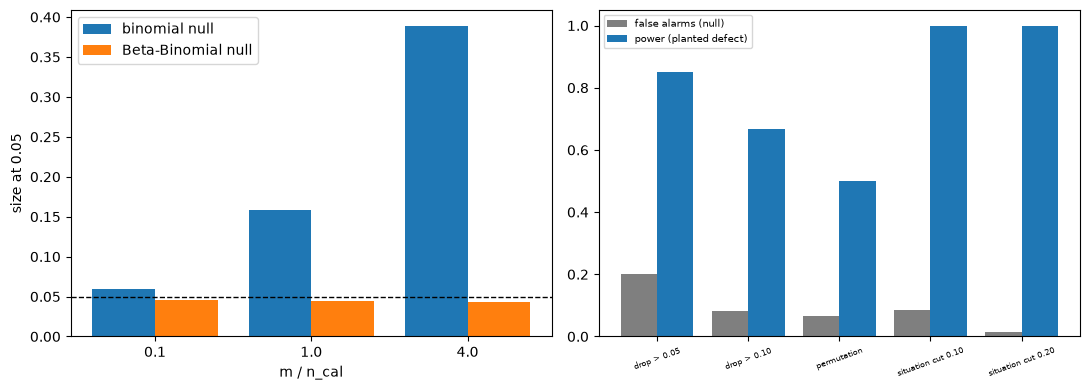

In [7]:
# Left: size of the coverage test by window ratio; right: false-alarm rate (grey) and power (blue) of the resilience and situation rules
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.0))
ratios = [f"{m / n:.1f}" for n, m in conformal_size]
position = np.arange(len(ratios))
left.bar(position - 0.2, [s[0] for s in conformal_size.values()], width=0.4, label="binomial null")
left.bar(position + 0.2, [s[1] for s in conformal_size.values()], width=0.4, label="Beta-Binomial null")
left.axhline(0.05, color="black", linestyle="--", linewidth=1)
left.set_xticks(position)
left.set_xticklabels(ratios)
left.set_xlabel("m / n_cal")
left.set_ylabel("size at 0.05")
left.legend()
names = ["drop > 0.05", "drop > 0.10", "permutation", "situation cut 0.10", "situation cut 0.20"]
null_rates = list(shift_rates[0.0][0]) + list(situation_rates[0.0])
power_rates = list(shift_rates[2.0][0]) + list(situation_rates[0.8])
index = np.arange(len(names))
right.bar(index - 0.2, null_rates, width=0.4, color="tab:gray", label="false alarms (null)")
right.bar(index + 0.2, power_rates, width=0.4, color="tab:blue", label="power (planted defect)")
right.set_xticks(index)
right.set_xticklabels(names, fontsize=6, rotation=20)
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **The binomial null makes the coverage test reject far too often once the test window is not small.** With exchangeable data and the nominal level 0.05, the binomial p-value falls below 0.05 in 0.0600 of the replications when the test window is a tenth of the calibration window (standard error 0.0061), in 0.1587 when the two windows are equal (0.0094) and in 0.3893 when the test window is four times the calibration window (0.0126). The Beta-Binomial p-value of the engine falls below 0.05 in 0.0460, 0.0440 and 0.0427 of them (standard errors from 0.0052 to 0.0054): below the nominal level at all three ratios, never above it. The committed Federal Reserve windows have a calibration window of 1,471 companies against test windows of 3,151 and 12,604, the regime where the two differ: the baseline window gives 0.523 (Beta-Binomial) and 0.313 (binomial), and for the 0.8800 coverage of the full shift the Beta-Binomial p-value is 0.0372 (amber) while the binomial one is 0.000258.
- **A fixed drop rule fires on a stable model; the permutation reference does not.** With no shift, the raw drop of the worst quarter by shift score has a mean of 0.0119 and a 95th percentile of 0.1203 over 60 replications. A rule "drop above 0.05" raises a false alarm in 0.2000 of them and "drop above 0.10" in 0.0833; the permutation rule (p at most 0.05, with 39 draws here) in 0.0667, which is within the standard error (0.0281) of the nominal level. Against the planted shift of 2 standard deviations the three rules detect it in 0.8500, 0.6667 and 0.5000 of the replications. So in this small design the permutation reference holds the false-alarm rate near its level and pays for it in power, because 250 evaluation rows and 39 draws make the reference coarse; the fixed cuts detect more because they also fire when there is nothing. The engine's default of 199 draws and larger samples narrow that cost, and this notebook does not measure it. The committed Federal Reserve row reads a drop of 0.0857 against a null that averages 0.0007 and has a 95th percentile of 0.0243 over 199 draws: p = 0.005, red.
- **The 0.20 cut point of the situation light removes most of the false alarms at no cost in power in this design.** With no group effect the share of significant complainants averages 0.0398, and exceeds the old cut 0.10 in 0.0850 of the 200 replications and the cut 0.20 in 0.0150; with the planted bias the share averages 0.7338 and exceeds both cuts in every replication. The engine's own documented measurement (a size of 0.039 at 0.20 and 0.194 at 0.10) uses another protocol and is not reproduced here: the direction agrees, the magnitude does not. The committed Delaware 2018 row has a share of 0.2629 against the cut 0.2: amber.
- **What this evidence supports for BS-10.** The three corrections are in use in the committed documents (both conformal p-values side by side, 199 permutation draws, the cut 0.2), and the engine's own functions on planted data show the size each one corrects: 0.1587 and 0.3893 for the binomial coverage test against about 0.044 for the Beta-Binomial one, 0.2000 and 0.0833 for fixed drop cuts against 0.0667 for the permutation reference, 0.0850 against 0.0150 for the two situation cuts. All the committed rows were baked with riskvalidation 0.8.1.

What the results do not show: the simulations are small (1,500, 60 and 200 replications) and each rate carries the standard error printed beside it; the shift design has few rows and 39 draws; the engine's own size-and-power suites, which are larger, are in the engine's repository and are not run here; the planted defects are synthetic; and a test with a good size and power on a plant says nothing yet about a real portfolio.

## Summary

- The binomial null makes the coverage test reject in 0.0600, 0.1587 and 0.3893 of exchangeable replications at test-to-calibration ratios of 0.1, 1 and 4, while the Beta-Binomial null of the engine stays at 0.0460, 0.0440 and 0.0427.
- A fixed AUC-drop rule on the worst subsample raises a false alarm in 0.2000 and 0.0833 of no-shift replications; the permutation reference in 0.0667, at a cost in power in this small design.
- The situation-testing amber cut 0.20 raises a false alarm in 0.0150 of null replications against 0.0850 for the cut 0.10, and both detect the planted bias in every replication.
- The committed C20 and C21 rows carry the corrections in use: both conformal p-values side by side, 199 permutation draws and the cut 0.2, baked with riskvalidation 0.8.1.
- Each rate is printed with its Monte Carlo standard error; the simulations are small, the plants synthetic, and the engine's larger size-and-power suites are not run here.

**What to try next.** Topic 14 measures the size and the power of the engine's whole catalogue on planted defects, with the same method at a larger scale.

## References

- Angelopoulos, A. N. and Bates, S. (2021), A gentle introduction to conformal prediction and distribution-free uncertainty quantification, arXiv 2107.07511. https://arxiv.org/abs/2107.07511
- PiML-Toolbox (Apache-2.0), outcome tests WeakSpot, Overfit, Reliability, Robustness and Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox
- Phipson, B. and Smyth, G. K. (2010), Permutation p-values should never be zero, Statistical Applications in Genetics and Molecular Biology 9(1). https://doi.org/10.2202/1544-6115.1585
- ECB (2025), Guide to internal models, the paragraphs on the randomness of the training process, overfitting, explainability and the justification of complexity (43, 59, 60, 62, 64 to 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Alvarez, J. M. and Ruggieri, S. (2025), Counterfactual situation testing: from single to multidimensional discrimination, Journal of Artificial Intelligence Research 82, arXiv 2502.01267. https://doi.org/10.1613/jair.1.17935
- Zieba, M., Tomczak, S. K. and Tomczak, J. M., Polish companies bankruptcy data, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data